# 04 — ResNet Regression Model (Channel 1)

**Goal:** Use one 64 × 64 Channel 1 (`irwin_cdr`) satellite image to predict `TARGET_WIND`, the six-hour-ahead cyclone wind speed in knots.

- Labels: `/content/data/samples_6h`
- Satellite patches: `/content/data/patches_full`
- Input: one 64 × 64 grayscale satellite image
- Target: `TARGET_WIND` (six-hour-ahead wind speed, knots)
- Model: a small ResNet-style network with residual/skip connections, trained from scratch
- Outputs: saved model, metrics JSON, and test-prediction CSV in Google Drive

**Note:** This is a regression model, not a cyclone-category classifier.

## 1. Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Extract the dataset archive

In [2]:
import os
import tarfile

archive = "/content/drive/MyDrive/cyclone/cyclone_data.tar.gz"
data_root = "/content/data"

required_dirs = [
    os.path.join(data_root, "samples_6h"),
    os.path.join(data_root, "patches_full"),
]

if all(os.path.exists(path) for path in required_dirs):
    print("Dataset folders already exist. Skipping extraction.")
else:
    if not os.path.exists(archive):
        raise FileNotFoundError(
            f"Archive not found: {archive}\n"
            "Check that cyclone_data.tar.gz is inside MyDrive/cyclone."
        )
    os.makedirs(data_root, exist_ok=True)
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(data_root)
    print("Dataset extraction finished.")

for path in required_dirs:
    print(path, "exists:", os.path.exists(path))

/tmp/ipykernel_518/676470383.py:22: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(data_root)


Dataset extraction finished.
/content/data/samples_6h exists: True
/content/data/patches_full exists: True


## 3. Load labels and satellite patches

In [3]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

labels_path = "/content/data/samples_6h"
patches_path = "/content/data/patches_full"

label_files = glob.glob(os.path.join(labels_path, "*.parquet"))
patch_files = glob.glob(os.path.join(patches_path, "*.parquet"))

print("Label parquet files:", len(label_files))
print("Patch parquet files:", len(patch_files))

if not label_files or not patch_files:
    raise FileNotFoundError(
        "Could not find parquet files. Check the extracted folder structure."
    )

L = pd.read_parquet(labels_path)
P = pd.read_parquet(patches_path)

L["ISO_TIME"] = pd.to_datetime(L["ISO_TIME"], errors="coerce")
P["T"] = pd.to_datetime(P["T"], errors="coerce")

print("Labels shape:", L.shape)
print("Patches shape:", P.shape)
print("Label columns:", L.columns.tolist())
print("Patch columns:", P.columns.tolist())
print("\nLabel split counts:")
print(L["SPLIT"].value_counts(dropna=False))

Label parquet files: 1
Patch parquet files: 1155
Labels shape: (4295, 8)
Patches shape: (10814, 5)
Label columns: ['SID', 'BASIN', 'ISO_TIME', 'LAT', 'LON', 'WIND_KT', 'TARGET_WIND', 'SPLIT']
Patch columns: ['SID', 'T', 'LAT', 'LON', 'PATCH']

Label split counts:
SPLIT
1_train    2806
3_test     1013
2_val       476
Name: count, dtype: int64


## 4. Assign the existing cyclone splits to patches

In [4]:
# Keep the same cyclone-level train/validation/test split used by the project.
cyclone_splits = L[["SID", "SPLIT"]].drop_duplicates()

multi_split_cyclones = (
    cyclone_splits.groupby("SID")["SPLIT"].nunique().gt(1).sum()
)
print("Cyclones appearing in multiple splits:", int(multi_split_cyclones))

if multi_split_cyclones:
    raise ValueError(
        "At least one cyclone appears in multiple splits. "
        "Resolve the split assignment before training to avoid leakage."
    )

P_split = P.merge(
    cyclone_splits,
    on="SID",
    how="left",
    validate="many_to_one"
)

P_split = P_split[
    P_split["SPLIT"].isin(["1_train", "2_val", "3_test"])
].copy()

print("Patch counts by split:")
print(P_split["SPLIT"].value_counts())

Cyclones appearing in multiple splits: 0
Patch counts by split:
SPLIT
1_train    7174
3_test     2691
2_val       949
Name: count, dtype: int64


## 5. Decode Channel 1 and match images to their wind-speed targets

In [5]:
# Each patch stores two 64x64 channels as float16 bytes.
# Channel 1 is values[0], the infrared-window channel used by the CNN notebook.

image_records = []
skipped_all_missing = 0
skipped_bad_shape = 0

for row in P_split.itertuples(index=False):
    values = np.frombuffer(row.PATCH, dtype=np.float16)

    if values.size != 2 * 64 * 64:
        skipped_bad_shape += 1
        continue

    patch = values.reshape(2, 64, 64)
    channel1 = patch[0].astype(np.float32)

    # Skip images with no usable Channel 1 pixels.
    if not np.isfinite(channel1).any():
        skipped_all_missing += 1
        continue

    image_records.append({
        "SID": row.SID,
        "T": row.T,
        "SPLIT": row.SPLIT,
        "IMAGE": channel1
    })

images_df = pd.DataFrame(image_records)

print("Patches assigned to a split:", len(P_split))
print("Usable Channel 1 images:", len(images_df))
print("Completely missing images skipped:", skipped_all_missing)
print("Invalid-shape patches skipped:", skipped_bad_shape)

label_targets = L[["SID", "ISO_TIME", "TARGET_WIND"]].copy()
label_targets = label_targets.dropna(
    subset=["SID", "ISO_TIME", "TARGET_WIND"]
)

duplicate_keys = label_targets.duplicated(["SID", "ISO_TIME"]).sum()
print("Duplicate non-missing label keys:", int(duplicate_keys))

if duplicate_keys:
    raise ValueError(
        "Duplicate (SID, ISO_TIME) target rows found. "
        "Inspect the label data before continuing."
    )

dataset_df = images_df.merge(
    label_targets,
    left_on=["SID", "T"],
    right_on=["SID", "ISO_TIME"],
    how="inner",
    validate="many_to_one"
)

dataset_df = dataset_df.dropna(subset=["TARGET_WIND"]).copy()
dataset_df["TARGET_WIND"] = dataset_df["TARGET_WIND"].astype(np.float32)

# Stable ordering helps ensure repeatable predictions and comparison files.
dataset_df = dataset_df.sort_values(["SID", "T"]).reset_index(drop=True)

print("\nMatched images with targets:", len(dataset_df))
print("Matched samples by split:")
print(dataset_df["SPLIT"].value_counts())
print("\nTarget wind speed (knots):")
print(dataset_df["TARGET_WIND"].describe())

Patches assigned to a split: 10814
Usable Channel 1 images: 10811
Completely missing images skipped: 3
Invalid-shape patches skipped: 0
Duplicate non-missing label keys: 0

Matched images with targets: 4290
Matched samples by split:
SPLIT
1_train    2801
3_test     1013
2_val       476
Name: count, dtype: int64

Target wind speed (knots):
count    4290.000000
mean       48.835663
std        24.553192
min        15.000000
25%        30.000000
50%        40.000000
75%        60.000000
max       165.000000
Name: TARGET_WIND, dtype: float64


## 6. Prepare train, validation, and test arrays

In [6]:
# Calculate normalization statistics from finite pixels in TRAIN images only.
train_rows = dataset_df[dataset_df["SPLIT"] == "1_train"]

if train_rows.empty:
    raise ValueError("No training images matched with target wind speeds.")

train_pixel_sum = 0.0
train_pixel_squared_sum = 0.0
train_pixel_count = 0

for image in train_rows["IMAGE"]:
    valid = image[np.isfinite(image)].astype(np.float64)
    train_pixel_sum += valid.sum()
    train_pixel_squared_sum += np.square(valid).sum()
    train_pixel_count += valid.size

if train_pixel_count == 0:
    raise ValueError("No valid pixels were found in the training images.")

pixel_mean = train_pixel_sum / train_pixel_count
pixel_variance = max(
    train_pixel_squared_sum / train_pixel_count - pixel_mean**2, 0.0
)
pixel_std = float(np.sqrt(pixel_variance))

if not np.isfinite(pixel_std) or pixel_std == 0:
    raise ValueError(f"Invalid training pixel standard deviation: {pixel_std}")

print("Training pixel mean:", pixel_mean)
print("Training pixel standard deviation:", pixel_std)

def prepare_image(image):
    image = image.astype(np.float32).copy()
    # Replace missing pixels with TRAINING mean; these become zero after standardization.
    image[~np.isfinite(image)] = pixel_mean
    image = (image - pixel_mean) / pixel_std
    return image[..., np.newaxis]  # (64, 64, 1)

arrays = {}
split_frames = {}

for split_name, short_name in [
    ("1_train", "train"),
    ("2_val", "val"),
    ("3_test", "test"),
]:
    part = dataset_df[dataset_df["SPLIT"] == split_name].copy().reset_index(drop=True)

    if part.empty:
        raise ValueError(f"No matched samples found for split {split_name}.")

    X = np.stack([prepare_image(img) for img in part["IMAGE"]]).astype(np.float32)
    y = part["TARGET_WIND"].to_numpy(dtype=np.float32)

    arrays[f"X_{short_name}"] = X
    arrays[f"y_{short_name}"] = y
    split_frames[short_name] = part

    print(f"{short_name}: X={X.shape}, y={y.shape}")

X_train, y_train = arrays["X_train"], arrays["y_train"]
X_val, y_val = arrays["X_val"], arrays["y_val"]
X_test, y_test = arrays["X_test"], arrays["y_test"]

print("\nMissing/non-finite values after preparation:")
print("Train:", int((~np.isfinite(X_train)).sum()))
print("Validation:", int((~np.isfinite(X_val)).sum()))
print("Test:", int((~np.isfinite(X_test)).sum()))

Training pixel mean: 239.26144846078967
Training pixel standard deviation: 31.93635833397661
train: X=(2801, 64, 64, 1), y=(2801,)
val: X=(476, 64, 64, 1), y=(476,)
test: X=(1013, 64, 64, 1), y=(1013,)

Missing/non-finite values after preparation:
Train: 0
Validation: 0
Test: 0


## 7. Preview a prepared Channel 1 image

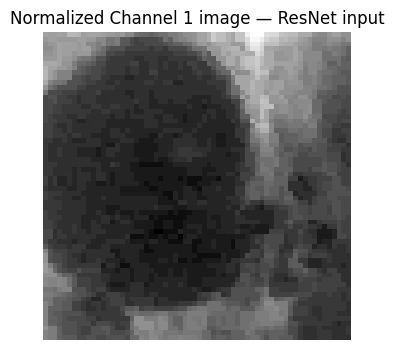

Example target wind speed (knots): 30.0


In [7]:
plt.figure(figsize=(4, 4))
plt.imshow(X_train[0, :, :, 0], cmap="gray")
plt.title("Normalized Channel 1 image — ResNet input")
plt.axis("off")
plt.show()

print("Example target wind speed (knots):", float(y_train[0]))

## 8. Build the ResNet model

This notebook uses a compact **ResNet-style architecture trained from scratch**. It accepts the project's grayscale 64 × 64 images directly, so we do not need to resize the images or convert them to three channels.

A residual block learns a transformation of its input and adds the original input through a skip connection. If the number of channels or spatial size changes, a projection shortcut aligns the shapes.

The final dense layer has one output because we are predicting a numerical wind speed.

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

def residual_block(x, filters, stride=1, block_name="res"):
    shortcut = x

    x = layers.Conv2D(
        filters, kernel_size=3, strides=stride, padding="same",
        use_bias=False, name=f"{block_name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{block_name}_bn1")(x)
    x = layers.Activation("relu", name=f"{block_name}_relu1")(x)

    x = layers.Conv2D(
        filters, kernel_size=3, strides=1, padding="same",
        use_bias=False, name=f"{block_name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{block_name}_bn2")(x)

    # Projection shortcut is required if spatial dimensions or channels change.
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, kernel_size=1, strides=stride, padding="same",
            use_bias=False, name=f"{block_name}_shortcut_conv"
        )(shortcut)
        shortcut = layers.BatchNormalization(
            name=f"{block_name}_shortcut_bn"
        )(shortcut)

    x = layers.Add(name=f"{block_name}_add")([x, shortcut])
    x = layers.Activation("relu", name=f"{block_name}_out")(x)
    return x

inputs = layers.Input(shape=(64, 64, 1), name="channel1_image")

x = layers.Conv2D(
    32, kernel_size=3, strides=1, padding="same",
    use_bias=False, name="stem_conv"
)(inputs)
x = layers.BatchNormalization(name="stem_bn")(x)
x = layers.Activation("relu", name="stem_relu")(x)

x = residual_block(x, 32, stride=1, block_name="res_block1")
x = residual_block(x, 32, stride=1, block_name="res_block2")
x = residual_block(x, 64, stride=2, block_name="res_block3")
x = residual_block(x, 64, stride=1, block_name="res_block4")
x = residual_block(x, 128, stride=2, block_name="res_block5")

x = layers.GlobalAveragePooling2D(name="global_average_pool")(x)
x = layers.Dense(64, activation="relu", name="regression_dense")(x)
x = layers.Dropout(0.25, name="regression_dropout")(x)
outputs = layers.Dense(1, activation="linear", name="predicted_wind_knots")(x)

resnet_model = Model(inputs=inputs, outputs=outputs, name="CycloneConnect_ResNet_Channel1")

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

resnet_model.summary()

Model: "CycloneConnect_ResNet_Channel1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ channel1_image      │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 64, 64,    │        288 │ channel1_image[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 64, 64,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_relu           │ (None, 64, 64,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block1_conv1    │ (None, 64, 64,    │      9,216 │ stem_relu[0][0]   │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block1_bn1      │ (None, 64, 64,    │        128 │ res_block1_conv1… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block1_relu1    │ (None, 64, 64,    │          0 │ res_block1_bn1[0… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block1_conv2    │ (None, 64, 64,    │      9,216 │ res_block1_relu1… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block1_bn2      │ (None, 64, 64,    │        128 │ res_block1_conv2… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block1_add      │ (None, 64, 64,    │          0 │ res_block1_bn2[0… │
│ (Add)               │ 32)               │            │ stem_relu[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block1_out      │ (None, 64, 64,    │          0 │ res_block1_add[0… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block2_conv1    │ (None, 64, 64,    │      9,216 │ res_block1_out[0… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block2_bn1      │ (None, 64, 64,    │        128 │ res_block2_conv1… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block2_relu1    │ (None, 64, 64,    │          0 │ res_block2_bn1[0… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block2_conv2    │ (None, 64, 64,    │      9,216 │ res_block2_relu1… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block2_bn2      │ (None, 64, 64,    │        128 │ res_block2_conv2… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block2_add      │ (None, 64, 64,    │          0 │ res_block2_bn2[0

 Total params: 409,377 (1.56 MB)

 Trainable params: 407,649 (1.56 MB)

 Non-trainable params: 1,728 (6.75 KB)

## 9. Train the ResNet model

In [9]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

history = resnet_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 46s 276ms/step - loss: 1068.8776 - mean_absolute_error: 24.7953 - val_loss: 681.4365 - val_mean_absolute_error: 21.4070 - learning_rate: 0.0010
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 410.9654 - mean_absolute_error: 15.2507 - val_loss: 1792.4352 - val_mean_absolute_error: 35.8933 - learning_rate: 0.0010
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 393.8332 - mean_absolute_error: 14.9469 - val_loss: 557.0900 - val_mean_absolute_error: 20.4385 - learning_rate: 0.0010
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 377.8305 - mean_absolute_error: 14.6142 - val_loss: 1025.0490 - val_mean_absolute_error: 26.6715 - learning_rate: 0.0010
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 369.5113 - mean_absolute_error: 14.5127 - val_loss: 586.3193 - val_mean_absolute_error: 19.9200 - learning_rate: 0.0010
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 359.1455 - mean_absolute_error: 14.3367 -

## 10. Plot training history

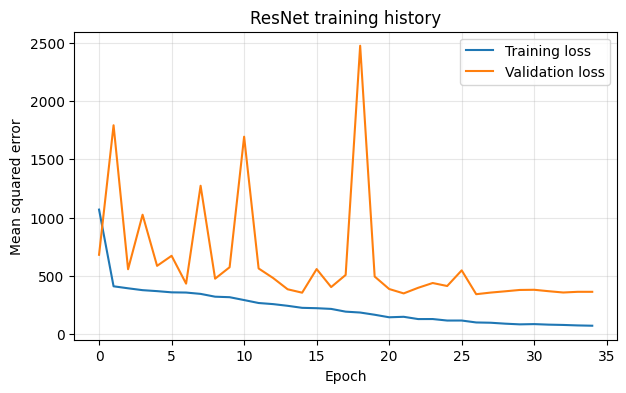

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("ResNet training history")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 11. Evaluate on the test set

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

test_predictions = resnet_model.predict(X_test, verbose=0).reshape(-1)

test_mae = float(mean_absolute_error(y_test, test_predictions))
test_rmse = float(np.sqrt(mean_squared_error(y_test, test_predictions)))

print("=== RESNET CHANNEL 1 TEST RESULTS ===")
print(f"Test samples: {len(y_test)}")
print(f"Test MAE:  {test_mae:.4f} knots")
print(f"Test RMSE: {test_rmse:.4f} knots")

=== RESNET CHANNEL 1 TEST RESULTS ===
Test samples: 1013
Test MAE:  11.3928 knots
Test RMSE: 15.0061 knots


## 12. Save the model, metrics, and test predictions to Google Drive

In [12]:
import json

output_dir = "/content/drive/MyDrive/cyclone/model_results"
os.makedirs(output_dir, exist_ok=True)

model_path = os.path.join(output_dir, "resnet_channel1_model.keras")
metrics_path = os.path.join(output_dir, "resnet_channel1_metrics.json")
predictions_path = os.path.join(output_dir, "resnet_channel1_test_predictions.csv")

resnet_model.save(model_path)

metrics = {
    "model": "ResNet-style CNN",
    "channel": 1,
    "input": "single 64x64 grayscale satellite image",
    "target": "TARGET_WIND (six-hour-ahead wind speed, knots)",
    "test_samples": int(len(y_test)),
    "test_mae_knots": float(test_mae),
    "test_rmse_knots": float(test_rmse),
    "normalization_train_pixel_mean": float(pixel_mean),
    "normalization_train_pixel_std": float(pixel_std),
    "seed": 42,
    "epochs_trained": int(len(history.history["loss"]))
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

test_rows = split_frames["test"][["SID", "T", "TARGET_WIND"]].copy().reset_index(drop=True)
predictions_df = test_rows.rename(columns={
    "T": "timestamp",
    "TARGET_WIND": "actual_wind_knots"
})
predictions_df["predicted_wind_knots"] = test_predictions
predictions_df.to_csv(predictions_path, index=False)

print("Saved model:", model_path)
print("Saved metrics:", metrics_path)
print("Saved test predictions:", predictions_path)
print("\nMetrics:")
print(json.dumps(metrics, indent=2))

Saved model: /content/drive/MyDrive/cyclone/model_results/resnet_channel1_model.keras
Saved metrics: /content/drive/MyDrive/cyclone/model_results/resnet_channel1_metrics.json
Saved test predictions: /content/drive/MyDrive/cyclone/model_results/resnet_channel1_test_predictions.csv

Metrics:
{
  "model": "ResNet-style CNN",
  "channel": 1,
  "input": "single 64x64 grayscale satellite image",
  "target": "TARGET_WIND (six-hour-ahead wind speed, knots)",
  "test_samples": 1013,
  "test_mae_knots": 11.39276123046875,
  "test_rmse_knots": 15.00612769531844,
  "normalization_train_pixel_mean": 239.26144846078967,
  "normalization_train_pixel_std": 31.93635833397661,
  "seed": 42,
  "epochs_trained": 35
}
